# Forecast initial-condition soil-moisture errors: plot

2x2 maps (bias top, spread bottom) of two experiments on a forecast start date, from the products of notebook 03.

## 1. Settings

In [1]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
WORKFLOW_NAME = "fcst_lnd_model_evaluation"

GROUP = "Jun2012"   # "Jan2012" or "Jun2012"
INIT_TIMES = {"Jan2012": "2012-01-01", "Jun2012": "2012-06-01"}
EXPERIMENTS = {"Jan2012": ["CAPT10-S0", "DART40-S0"], "Jun2012": ["CAPT10-S1", "DART40-S1"]}   # left, right
OBS_KEY = "ESA_CCI"
VARIABLE = "SOILWATER_10CM"
RUN, FREQ = "fc", "daily"

BIAS_LEVELS = (-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10)
SPREAD_LEVELS = (0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50)
SMOOTH = True   # visualization-only Gaussian smoothing
SMOOTH_SIGMA_BIAS = 1.0
SMOOTH_SIGMA_SPREAD = 0.7
STIPPLE = False
FIGURE_DPI = 200

## 2. Project setup

In [2]:
import sys
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
WORKFLOW_DATA_DIR, WORKFLOW_FIGURE_DIR = workflow_output_dirs(WORKFLOW_NAME, output_root=DIAGNOSTIC_OUTPUT_ROOT)

import pandas as pd
import cmocean
from util.initial_lnd_soil_error import SoilErrorMapPlotConfig, SoilErrorMapPlotter

init_time = pd.to_datetime(INIT_TIMES[GROUP])
product = WORKFLOW_DATA_DIR / "initial_condition_error" / f"soil_bias_{GROUP}_{FREQ}_{RUN}_{OBS_KEY}_{VARIABLE}_{init_time:%Y%m%d}.nc"
if not product.is_file():
    raise FileNotFoundError(f"{product} not found; run 03_process_initial_condition_errors first.")
figure_dir = WORKFLOW_FIGURE_DIR / "initial_condition_error"
figure_dir.mkdir(parents=True, exist_ok=True)

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 3. Plot

sh: getfattr: command not found


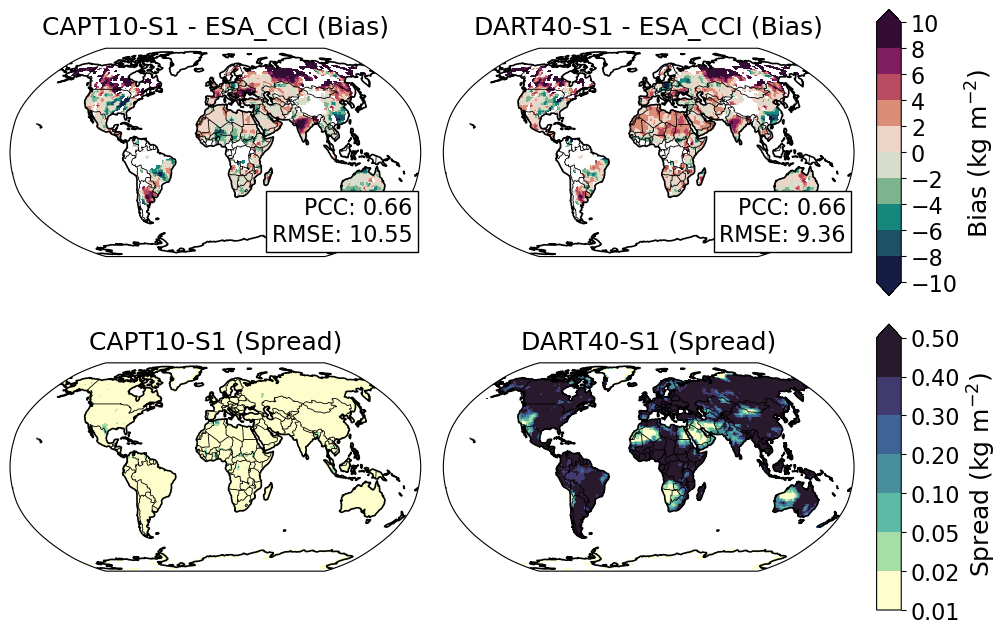

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/initial_condition_error/soil_diag_Jun2012_SOILWATER_10CM_20120601.pdf


In [3]:
plotter = SoilErrorMapPlotter(SoilErrorMapPlotConfig(
    bias_levels=BIAS_LEVELS, spread_levels=SPREAD_LEVELS,
    bias_cmap=cmocean.cm.curl, spread_cmap=cmocean.cm.deep,
    stipple=STIPPLE, smooth=SMOOTH, smooth_sigma_bias=SMOOTH_SIGMA_BIAS, smooth_sigma_spread=SMOOTH_SIGMA_SPREAD,
))
output = figure_dir / f"soil_diag_{GROUP}_{VARIABLE}_{init_time:%Y%m%d}.pdf"
left, right = EXPERIMENTS[GROUP]
plotter.plot_2x2(nc_file=product, exp_left=left, exp_right=right, time_index=0,
                 obs_label=OBS_KEY, out_png=output, show=True, dpi=FIGURE_DPI)
print(f"[FIGURE] {output}")